# Results: CNN-BiLSTM heart rate from PPG

Evaluates `cache/best.pt` on the held-out **test subjects** (same subject-wise split as `scripts/train.py`, seed 42).

- **Reference**: ECG-derived BPM (neurokit2 R-peaks, `bpm.ground_truth.ecg_to_hr_curve`), averaged over each 10 s window.
- **NN**: CNN-BiLSTM prediction from the bandpass-filtered PPG window.
- **Baseline**: classical PPG spectral peak (dominant FFT frequency in 0.5-3.5 Hz) on the same window, so the NN has a non-learned method to beat.

Prerequisite: `scripts/build_manifest.py`, `scripts/build_cache.py`, `scripts/train.py` have been run.

The discussion text under each figure refers to the outputs saved in this notebook; re-check it after retraining.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from scipy import stats
from sklearn.metrics import roc_auc_score, roc_curve

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from bpm.cache import WINDOW_S
from bpm.data_loading import load_subject_npz, subjects_by_dataset_from_manifest
from bpm.dataset import zscore_window
from bpm.model import CNNBiLSTM
from bpm.split import subject_wise_split

MANIFEST_PATH = ROOT / "cache" / "manifest.csv"
CACHE_DIR = ROOT / "cache" / "windows"
CHECKPOINT_PATH = ROOT / "cache" / "best.pt"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
FS = 100

# categorical slots 1-3 of the dataviz reference palette (validated all-pairs)
C_NN, C_BASE, C_3 = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "lines.linewidth": 2})

## Predictions on the test set

In [2]:
def predict(model, windows, batch=512):
    out = []
    with torch.no_grad():
        for i in range(0, len(windows), batch):
            x = torch.from_numpy(zscore_window(windows[i:i + batch])).float().to(DEVICE)
            out.append(model(x).cpu().numpy())
    return np.concatenate(out)


def spectral_peak_bpm(windows, lo=0.5, hi=3.5, n_fft=8192):
    sig = windows[:, 0] - windows[:, 0].mean(axis=-1, keepdims=True)
    spec = np.abs(np.fft.rfft(sig * np.hanning(sig.shape[-1]), n=n_fft))
    freqs = np.fft.rfftfreq(n_fft, 1 / FS)
    band = (freqs >= lo) & (freqs <= hi)
    return freqs[band][spec[:, band].argmax(axis=1)] * 60


split = subject_wise_split(subjects_by_dataset_from_manifest(MANIFEST_PATH), seed=42)
model = CNNBiLSTM().to(DEVICE)
model.load_state_dict(torch.load(CHECKPOINT_PATH, map_location=DEVICE))
model.eval()

rows = []
for sid in sorted(split["test"]):
    data = load_subject_npz(sid, CACHE_DIR)
    if data is None or len(data["labels"]) == 0:
        continue
    rows.append(pd.DataFrame({
        "subject": sid,
        "dataset": data["dataset_source"].astype(str),
        "window_idx": np.arange(len(data["labels"])),
        "ecg": data["labels"],
        "nn": predict(model, data["windows"]),
        "baseline": spectral_peak_bpm(data["windows"]),
    }))
df = pd.concat(rows, ignore_index=True)
df["err_nn"] = df.nn - df.ecg
df["err_base"] = df.baseline - df.ecg
print(f"{len(df)} test windows, {df.subject.nunique()} subjects, device={DEVICE}")
df.groupby("dataset").subject.agg(["nunique", "size"]).rename(columns={"nunique": "subjects", "size": "windows"})

8305 test windows, 7 subjects, device=cuda


,subjects,windows
dataset,,
multisite-ppg,3,6000
wrist-finger-ppg,4,2305


## Summary metrics

MAE / RMSE are window-level (pooled) here; `scripts/evaluate.py` reports subject-macro MAE. Bias and limits of agreement (LoA = bias ± 1.96 SD) are from Bland-Altman.

In [3]:
def metrics(g):
    out = {}
    for name in ("nn", "baseline"):
        e = g[name] - g.ecg
        out[(name, "MAE")] = e.abs().mean()
        out[(name, "RMSE")] = np.sqrt((e ** 2).mean())
        out[(name, "bias")] = e.mean()
        out[(name, "LoA ±")] = 1.96 * e.std()
        out[(name, "Pearson r")] = stats.pearsonr(g.ecg, g[name])[0]
        out[(name, "within 5 BPM %")] = 100 * (e.abs() <= 5).mean()
    return pd.Series(out)

summary = pd.concat([df.groupby("dataset").apply(metrics, include_groups=False),
                     metrics(df).to_frame("all").T])
summary.round(2)

nn                                                \
                    MAE   RMSE   bias  LoA ± Pearson r within 5 BPM %   
multisite-ppg     13.17  20.18 -11.55  32.43      0.09          34.33   
wrist-finger-ppg   3.68   5.12   2.05   9.20      0.81          74.97   
all               10.54  17.36  -7.78  30.42      0.41          45.61   

                 baseline                                                 
                      MAE   RMSE   bias   LoA ± Pearson r within 5 BPM %  
multisite-ppg       44.99  59.12 -15.31  111.92     -0.04          27.48  
wrist-finger-ppg     2.57   7.08  -1.28   13.65      0.71          93.58  
all                 33.22  50.39 -11.42   96.19      0.02          45.83

**What it shows:** agreement statistics per sub-dataset and pooled. MAE/RMSE are the average error size (RMSE punishes large errors more), bias is the mean signed error, LoA ± is the half-width of the 95% limits of agreement, Pearson r measures how well predictions track changes in the reference.

**Discussion:** On `wrist-finger-ppg` the NN is usable (MAE 3.7 BPM, r = 0.81, 75% of windows within 5 BPM), but the simple spectral baseline is even better there (MAE 2.6, 94% within 5 BPM): on clean, resting signals a learned model adds little. On `multisite-ppg` the NN barely tracks heart rate (r = 0.09, bias −11.6 BPM), although it is still about 3x better than the baseline, which fails badly on this data. The pooled "all" row is dominated by multisite (6000 of 8305 windows).

## Predicted vs ECG-derived BPM

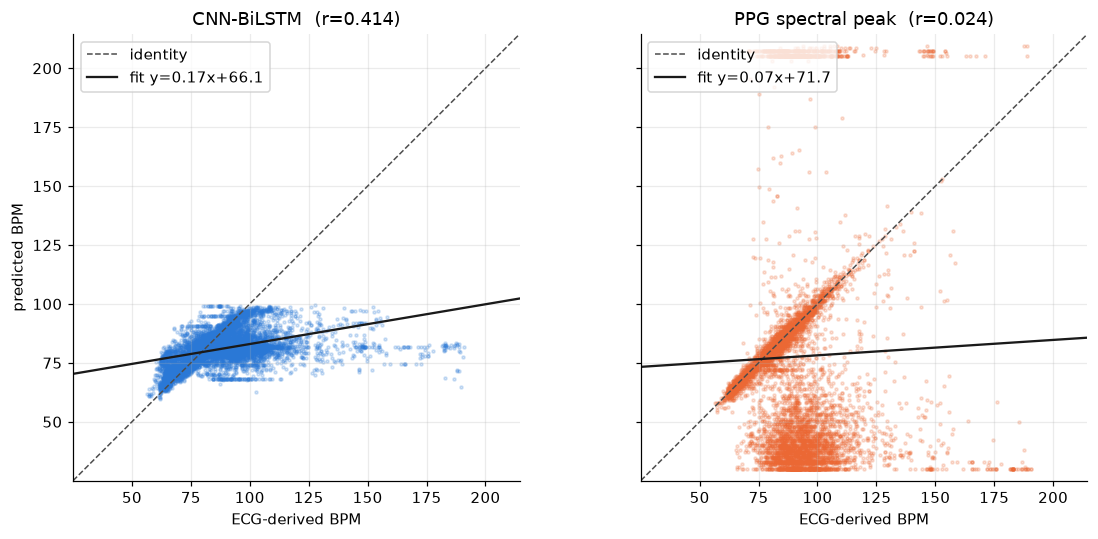

In [4]:
lims = [df[["ecg", "nn", "baseline"]].min().min() - 5, df[["ecg", "nn", "baseline"]].max().max() + 5]
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)
for ax, col, color, label in [(axes[0], "nn", C_NN, "CNN-BiLSTM"), (axes[1], "baseline", C_BASE, "PPG spectral peak")]:
    ax.scatter(df.ecg, df[col], s=4, alpha=0.2, color=color, rasterized=True)
    ax.plot(lims, lims, color="0.3", lw=1, ls="--", label="identity")
    slope, icpt, r, *_ = stats.linregress(df.ecg, df[col])
    xs = np.array(lims)
    ax.plot(xs, slope * xs + icpt, color="0.1", lw=1.5, label=f"fit y={slope:.2f}x+{icpt:.1f}")
    ax.set(title=f"{label}  (r={r:.3f})", xlabel="ECG-derived BPM", xlim=lims, ylim=lims, aspect="equal")
    ax.legend(loc="upper left")
axes[0].set_ylabel("predicted BPM")
fig.tight_layout()

**What it shows:** each dot is one 10 s window. x is the ECG-derived reference, y the prediction. Points on the dashed identity line are perfect; the solid line is a least-squares fit.

**Discussion:** The NN fit has slope 0.17: predictions are squeezed into roughly 65-100 BPM, and windows with ECG > 110 BPM are still predicted around 80 BPM. This is regression to the mean, the network falls back to a typical value when it cannot read the PPG. The baseline is exact when it works (dense cloud on the identity line) but has two failure clusters: a band at 30-50 BPM (locking onto low-frequency or half-rate components) and a row at about 205 BPM (the upper band edge). Those failures push its r to about 0.

## Bland-Altman: ECG method vs NN

Agreement between the ECG R-peak reference and the network (top row), with the PPG spectral baseline below for comparison.

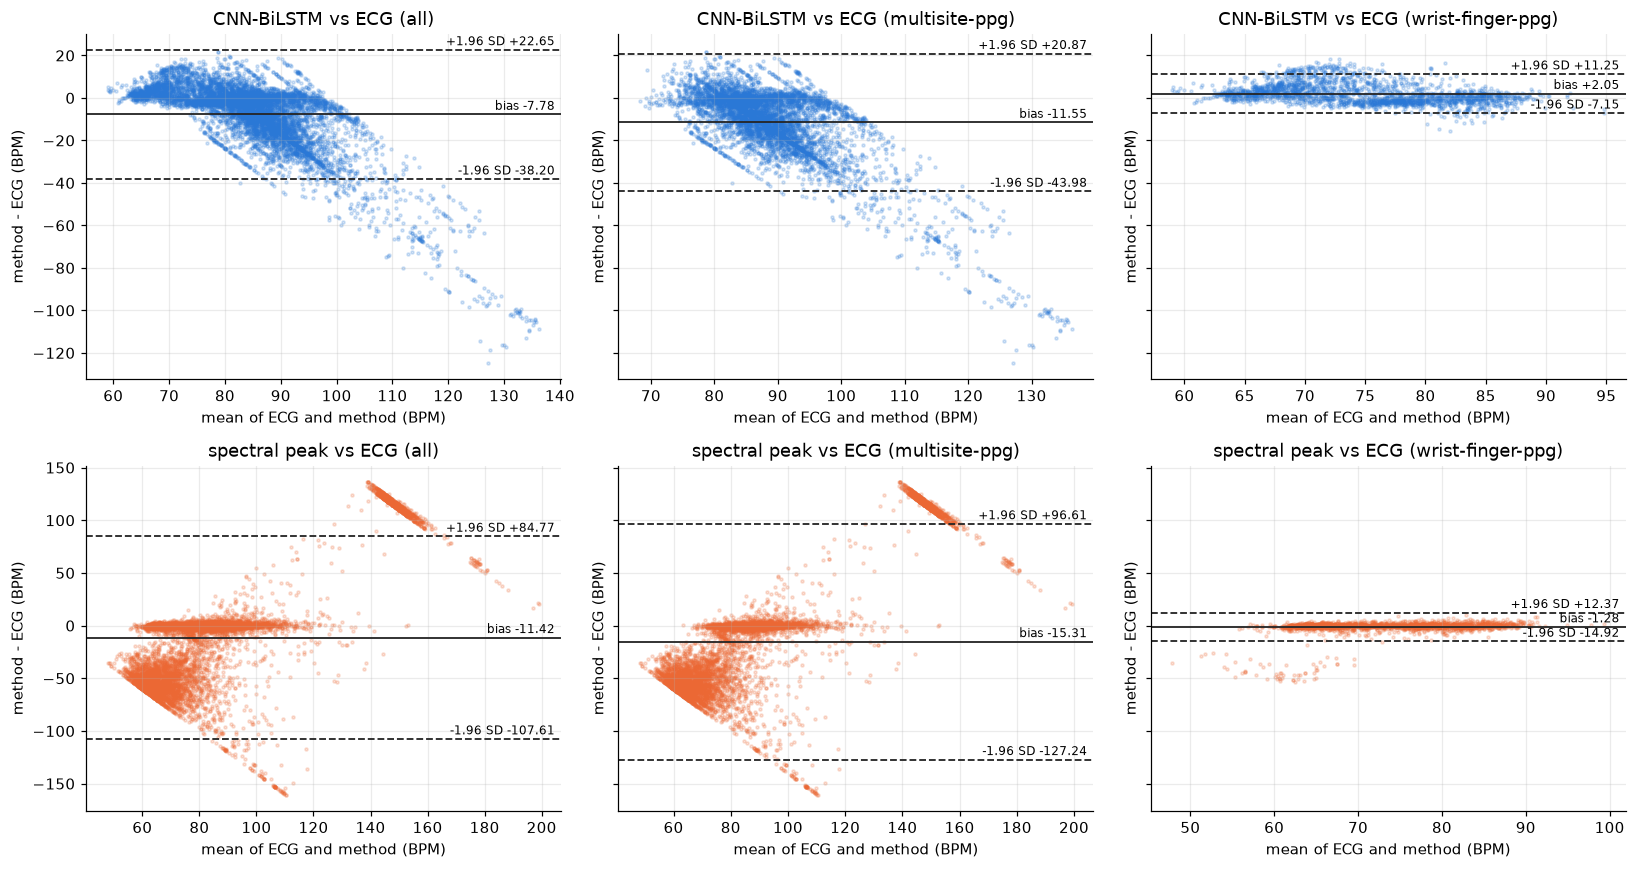

In [5]:
def bland_altman(ax, ref, test, color, title):
    mean, diff = (ref + test) / 2, test - ref
    bias, sd = diff.mean(), diff.std()
    ax.scatter(mean, diff, s=4, alpha=0.2, color=color, rasterized=True)
    for y, ls, txt in [(bias, "-", f"bias {bias:+.2f}"), (bias + 1.96 * sd, "--", f"+1.96 SD {bias + 1.96 * sd:+.2f}"),
                       (bias - 1.96 * sd, "--", f"-1.96 SD {bias - 1.96 * sd:+.2f}")]:
        ax.axhline(y, color="0.15", ls=ls, lw=1.2)
        ax.annotate(txt, (1, y), xycoords=("axes fraction", "data"), xytext=(-4, 3),
                    textcoords="offset points", ha="right", fontsize=8)
    ax.set(title=title, xlabel="mean of ECG and method (BPM)", ylabel="method - ECG (BPM)")

groups = ["all"] + sorted(df.dataset.unique())
fig, axes = plt.subplots(2, len(groups), figsize=(5 * len(groups), 8), sharey="row")
for j, g in enumerate(groups):
    sub = df if g == "all" else df[df.dataset == g]
    bland_altman(axes[0, j], sub.ecg, sub.nn, C_NN, f"CNN-BiLSTM vs ECG ({g})")
    bland_altman(axes[1, j], sub.ecg, sub.baseline, C_BASE, f"spectral peak vs ECG ({g})")
fig.tight_layout()

**What it shows:** x is the mean of the two methods, y the difference (method − ECG). The solid line is the bias, the dashed lines are the 95% limits of agreement (bias ± 1.96 SD). Good agreement means a narrow band around 0 with no slope.

**Discussion:** On `wrist-finger-ppg` the NN has a small bias (+2.1 BPM) and limits of about −7 to +11 BPM, which is close to common wearable accuracy targets. On `multisite-ppg` the bias is −11.6 BPM with limits of −44 to +21 BPM, and the cloud slopes downward: the higher the heart rate, the more the NN underestimates (proportional bias). The straight diagonal streaks are windows where the NN outputs almost the same value while the true HR varies. The baseline's limits are very wide on multisite (−127 to +97 BPM), driven by its gross failures; on wrist-finger it is tight apart from a cluster of half-rate errors near −40 BPM.

## ROC / AUROC: tachycardia and bradycardia detection

HR estimation is regression, so ROC needs a binary task. Positives are windows where the **ECG** reference crosses a clinical threshold; the score is the method's predicted BPM (negated for bradycardia).

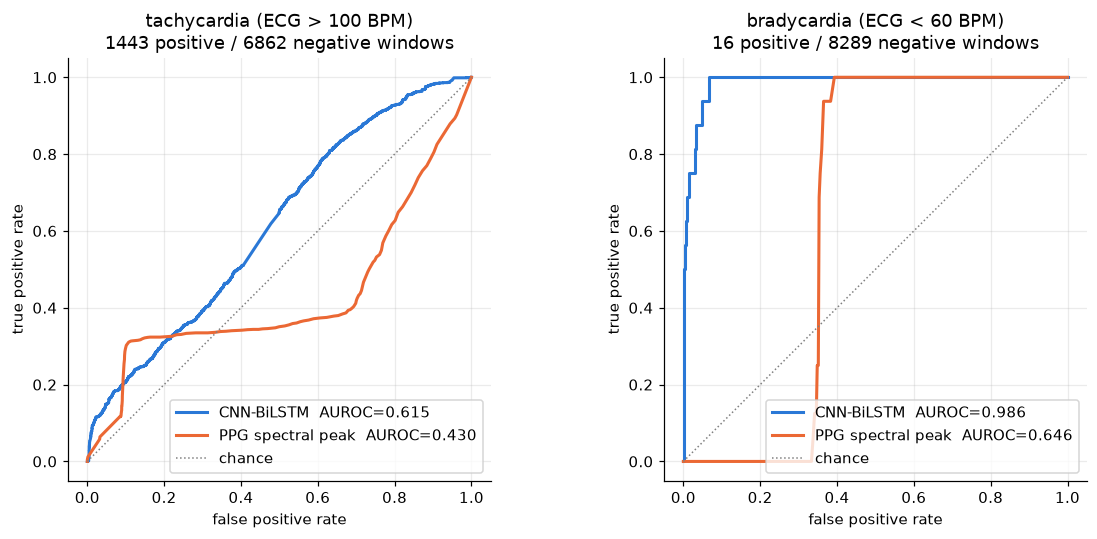

In [6]:
tasks = {"tachycardia (ECG > 100 BPM)": (df.ecg > 100, 1), "bradycardia (ECG < 60 BPM)": (df.ecg < 60, -1)}
fig, axes = plt.subplots(1, len(tasks), figsize=(11, 5))
for ax, (title, (y, sign)) in zip(axes, tasks.items()):
    n_pos = int(y.sum())
    if n_pos == 0 or n_pos == len(y):
        ax.set_title(f"{title}\nno positives/negatives in test set")
        continue
    for col, color, label in [("nn", C_NN, "CNN-BiLSTM"), ("baseline", C_BASE, "PPG spectral peak")]:
        fpr, tpr, _ = roc_curve(y, sign * df[col])
        ax.plot(fpr, tpr, color=color, label=f"{label}  AUROC={roc_auc_score(y, sign * df[col]):.3f}")
    ax.plot([0, 1], [0, 1], color="0.5", lw=1, ls=":", label="chance")
    ax.set(title=f"{title}\n{n_pos} positive / {len(y) - n_pos} negative windows",
           xlabel="false positive rate", ylabel="true positive rate", aspect="equal")
    ax.legend(loc="lower right")
fig.tight_layout()

**What it shows:** each curve sweeps a decision threshold over the predicted BPM and plots true positive rate against false positive rate. AUROC is the chance that a random positive window gets a higher score than a random negative one: 0.5 is chance, 1.0 is perfect.

**Discussion:** For tachycardia the NN reaches only 0.615, barely above chance, because it rarely predicts above 100 BPM (see the scatter plot). The baseline is below chance (0.43) because its failures at high heart rate land at low values. For bradycardia the NN looks excellent (0.986), but there are only 16 positive windows, so this number is not reliable. The baseline's jump at FPR ≈ 0.35 comes from the windows where it locks onto low frequencies and therefore looks bradycardic.

## Error distribution

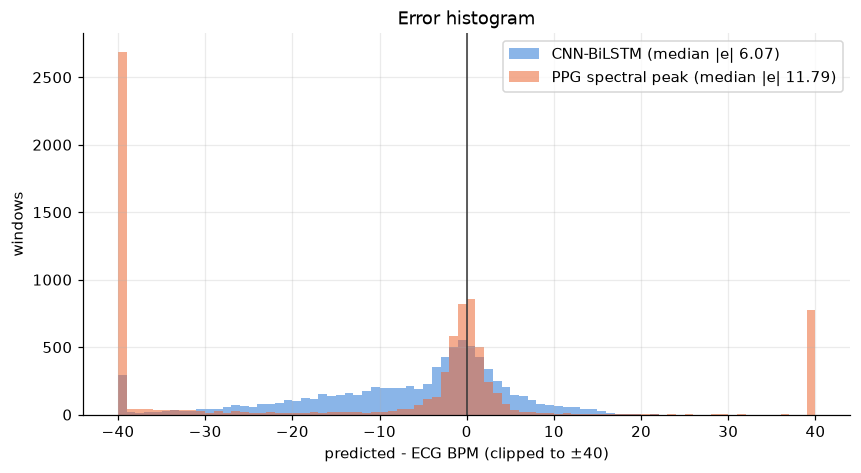

In [7]:
bins = np.linspace(-40, 40, 81)
fig, ax = plt.subplots(figsize=(9, 4.5))
for col, color, label in [("err_nn", C_NN, "CNN-BiLSTM"), ("err_base", C_BASE, "PPG spectral peak")]:
    ax.hist(df[col].clip(-40, 40), bins=bins, color=color, alpha=0.55, label=f"{label} (median |e| {df[col].abs().median():.2f})")
ax.axvline(0, color="0.2", lw=1)
ax.set(xlabel="predicted - ECG BPM (clipped to ±40)", ylabel="windows", title="Error histogram")
ax.legend();

**What it shows:** the distribution of signed errors (prediction − ECG). Errors beyond ±40 BPM are clipped, so the outer bars collect all gross failures.

**Discussion:** The NN errors form a broad peak around 0 (median |error| 6.1 BPM) with a long left tail, which is the underestimation seen above. The baseline has a sharper peak at 0, so when it is right it is very right, but about 2700 windows fall at −40 and about 780 at +40. The NN fails gradually, the baseline fails all-or-nothing.

## Absolute error by true heart-rate range

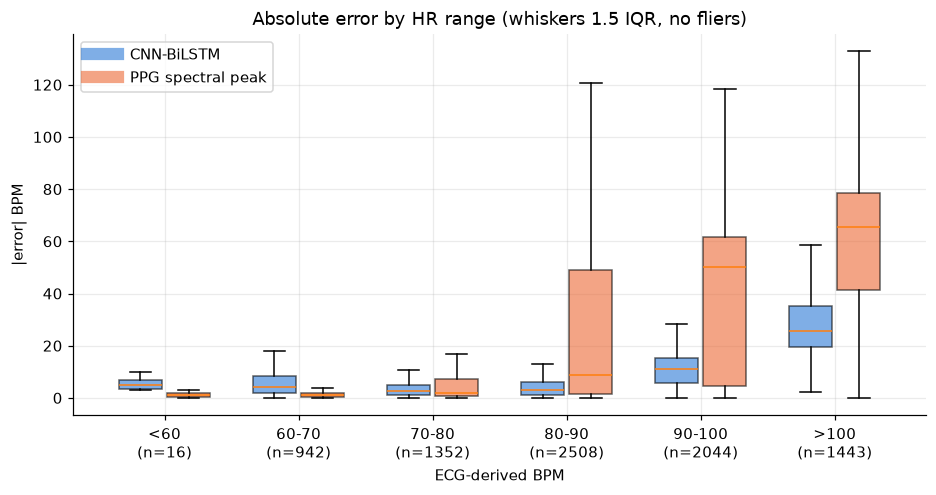

In [8]:
edges = [0, 60, 70, 80, 90, 100, 300]
labels = ["<60", "60-70", "70-80", "80-90", "90-100", ">100"]
df["hr_bin"] = pd.cut(df.ecg, edges, labels=labels, right=False)
fig, ax = plt.subplots(figsize=(10, 4.5))
pos = np.arange(len(labels))
for off, col, color, name in [(-0.18, "err_nn", C_NN, "CNN-BiLSTM"), (0.18, "err_base", C_BASE, "PPG spectral peak")]:
    data = [df.loc[df.hr_bin == b, col].abs().values for b in labels]
    bp = ax.boxplot([d if len(d) else [np.nan] for d in data], positions=pos + off, widths=0.32,
                    showfliers=False, patch_artist=True)
    for patch in bp["boxes"]:
        patch.set(facecolor=color, alpha=0.6)
    ax.plot([], [], color=color, lw=8, alpha=0.6, label=name)
counts = df.hr_bin.value_counts().reindex(labels)
ax.set_xticks(pos, [f"{b}\n(n={c})" for b, c in zip(labels, counts)])
ax.set(xlabel="ECG-derived BPM", ylabel="|error| BPM", title="Absolute error by HR range (whiskers 1.5 IQR, no fliers)")
ax.legend();

**What it shows:** absolute error grouped by the true (ECG) heart rate, with the number of windows per range under each label. Boxes span the 25th-75th percentile, the line inside is the median.

**Discussion:** NN error stays around 3-5 BPM up to 90 BPM, then rises steeply: median about 11 BPM at 90-100 and about 26 BPM above 100. The baseline is better below 80 BPM but collapses above it. HR range and sub-dataset are confounded here: most high-HR windows come from the free-living multisite recordings, so part of this trend is signal quality, not heart rate itself. The <60 bin has only 16 windows.

## Per-subject MAE

,dataset,subject,nn,baseline,windows
0,multisite-ppg,multisite_P10,9.480000,46.82,2000
2,multisite-ppg,multisite_P3,13.900000,40.69,2000
1,multisite-ppg,multisite_P17,16.139999,47.46,2000
6,wrist-finger-ppg,wristfinger_25,1.880000,2.11,530
3,wrist-finger-ppg,wristfinger_05,2.180000,4.09,541
4,wrist-finger-ppg,wristfinger_16,5.100000,3.17,573
5,wrist-finger-ppg,wristfinger_20,5.120000,1.18,661


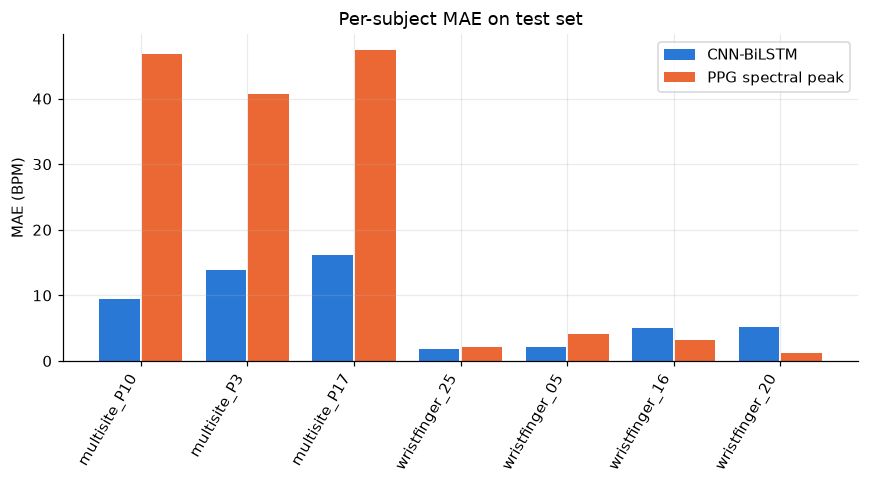

In [9]:
per_subj = df.groupby(["dataset", "subject"]).agg(
    nn=("err_nn", lambda e: e.abs().mean()), baseline=("err_base", lambda e: e.abs().mean()),
    windows=("ecg", "size")).reset_index().sort_values(["dataset", "nn"])
fig, ax = plt.subplots(figsize=(max(8, 0.55 * len(per_subj)), 4.5))
x = np.arange(len(per_subj))
ax.bar(x - 0.2, per_subj.nn, 0.38, color=C_NN, label="CNN-BiLSTM")
ax.bar(x + 0.2, per_subj.baseline, 0.38, color=C_BASE, label="PPG spectral peak")
ax.set_xticks(x, per_subj.subject, rotation=60, ha="right")
ax.set(ylabel="MAE (BPM)", title="Per-subject MAE on test set")
ax.legend()
fig.tight_layout()
per_subj.round(2)

**What it shows:** mean absolute error for each test subject, grouped by sub-dataset.

**Discussion:** The difference between sub-datasets is much larger than between subjects: multisite subjects range 9.5-16 BPM, wrist-finger subjects 1.9-5.1 BPM. The baseline beats the NN on two of the four wrist-finger subjects (16 and 20). With only 7 test subjects, each sub-dataset result rests on 3-4 people, so treat these numbers as indicative.

## Example HR trace

Windows of `wrist-finger-ppg` subjects are stored in recording order (no random cap), so consecutive windows form a time series (2 s stride; jumps occur at trial boundaries). Multisite windows are randomly subsampled, so they are not plotted as a trace.

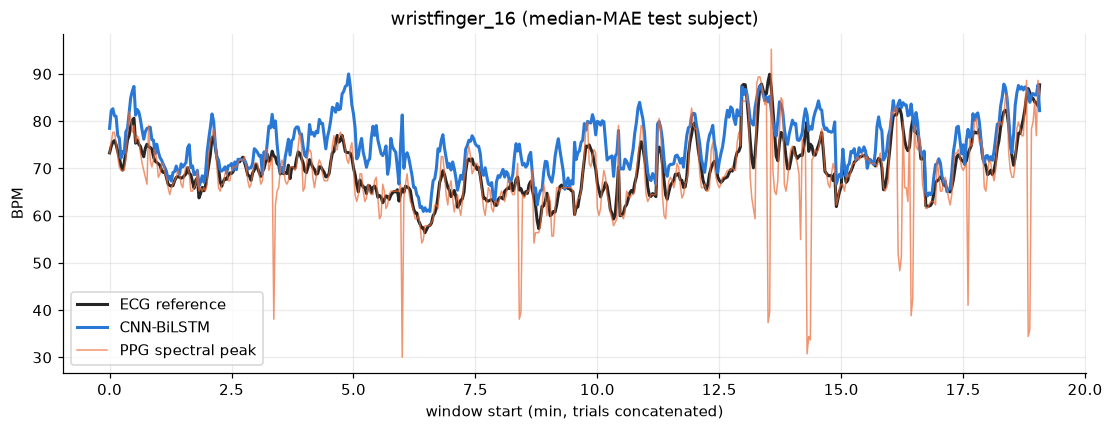

In [10]:
wf = df[df.dataset == "wrist-finger-ppg"]
if wf.empty:
    print("no wrist-finger-ppg subject in test set")
else:
    sid = wf.groupby("subject").err_nn.apply(lambda e: e.abs().mean()).sort_values().index[len(wf.subject.unique()) // 2]
    s = wf[wf.subject == sid]
    t = s.window_idx * 2 / 60
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(t, s.ecg, color="0.15", label="ECG reference")
    ax.plot(t, s.nn, color=C_NN, label="CNN-BiLSTM")
    ax.plot(t, s.baseline, color=C_BASE, lw=1, alpha=0.7, label="PPG spectral peak")
    ax.set(xlabel="window start (min, trials concatenated)", ylabel="BPM", title=f"{sid} (median-MAE test subject)")
    ax.legend()

**What it shows:** ECG reference, NN and baseline over consecutive windows for the median-MAE wrist-finger test subject.

**Discussion:** The NN follows the trend of the reference but is smoother and often a few BPM too high, with longer overshoots around minutes 5 and 10-12. The baseline hugs the reference closely most of the time but drops to 30-50 BPM for single windows; smoothing over neighbouring windows (e.g. a median filter) would remove most of those.

## Notes

- No training curves: `scripts/train.py` only prints per-epoch loss, it does not save history.
- ROC curves depend on how many test windows cross the thresholds; check the positive counts in the titles before reading too much into an AUROC.
- Overall: the NN works on short controlled recordings but underestimates high heart rates and barely tracks HR on the free-living multisite data, which is where most of the error comes from.